In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from model_sampler import DDIMSampler
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED

In [3]:
dataset = build_dataset('test')

In [4]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)

In [9]:
baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  baseline_results.append(ModelResults('112-beamdiff-bf16', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('136-beamdiff-bf16-2', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('137-beamdiff-bf16-3', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('138-beamdiff-bf16-4', sampling_name, 199, 'test', dataset))
  baseline_results.append(ModelResults('139-beamdiff-bf16-5', sampling_name, 199, 'test', dataset))

baseline_comparison = ModelComparison(baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

# Basic Caching

In [5]:
baseline = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
head_caching = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-head-1000', 199, 'test', dataset)

In [6]:
head_caching_comparison = ModelComparison([baseline, head_caching], ['Without Caching', 'With Head Caching'])

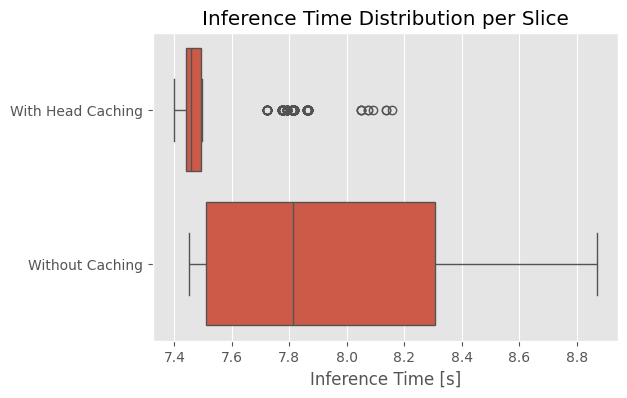

In [7]:
_ = head_caching_comparison.plot_inference_times('slice', 'seconds')

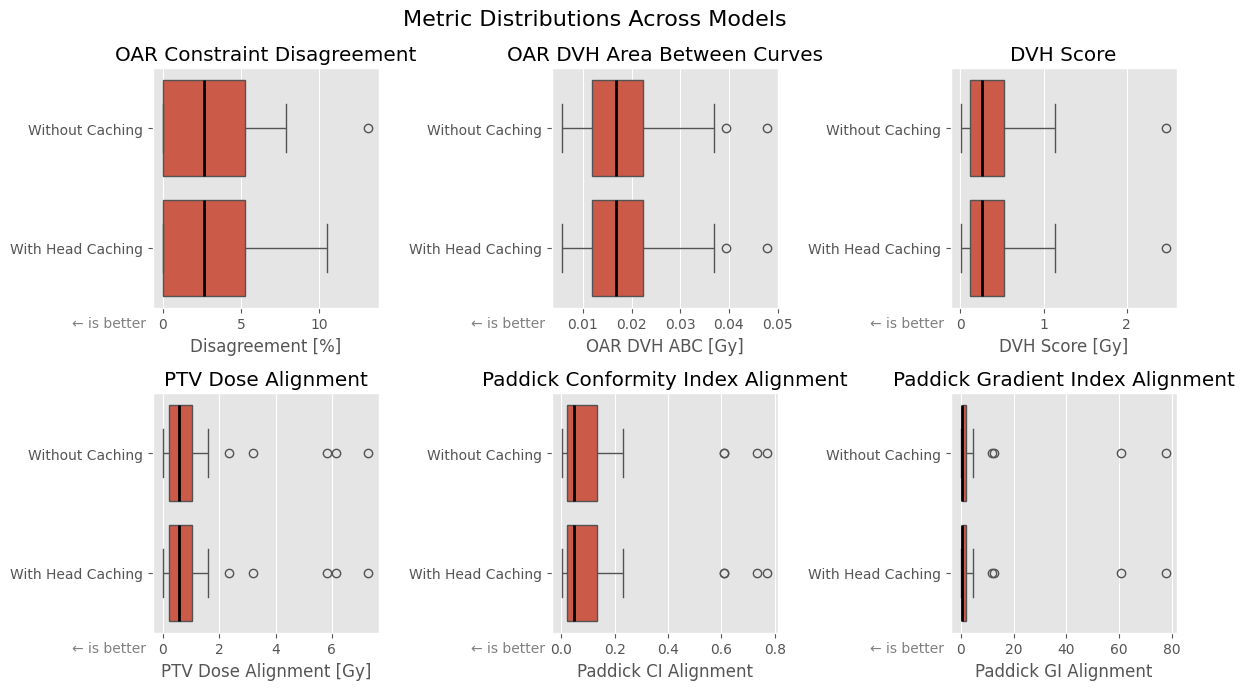

In [8]:
_ = head_caching_comparison.plot_metric_distributions(METRICS_PRED)

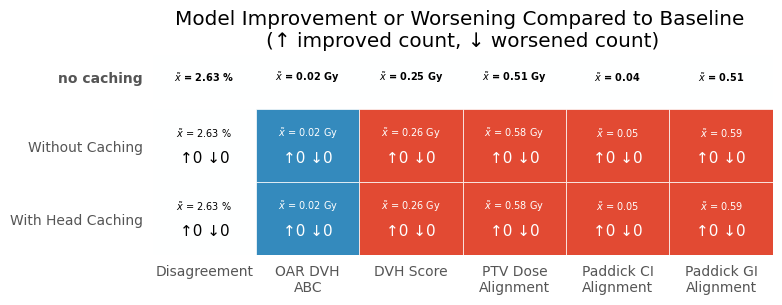

In [11]:
_ = head_caching_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=1,
  worsened_q=0,
  sort=False,
  baseline_label='no caching'
)

# Uniform Caching

In [12]:
enc1_int3 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval3-1000', 199, 'test', dataset)
enc1_int5 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval5-1000', 199, 'test', dataset)
enc1_int10 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval10-1000', 199, 'test', dataset)
enc1_int20 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval20-1000', 199, 'test', dataset)

enc2_int3 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval3-1000', 199, 'test', dataset)
enc2_int5 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-1000', 199, 'test', dataset)
enc2_int10 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval10-1000', 199, 'test', dataset)
enc2_int20 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval20-1000', 199, 'test', dataset)

enc3_int3 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval3-1000', 199, 'test', dataset)
enc3_int5 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval5-1000', 199, 'test', dataset)
enc3_int10 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval10-1000', 199, 'test', dataset)
enc3_int20 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval20-1000', 199, 'test', dataset)
enc3_int50 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval50-1000', 199, 'test', dataset)
enc3_int100 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval100-1000', 199, 'test', dataset)
enc3_int200 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval200-1000', 199, 'test', dataset)
enc3_inf = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-1000', 199, 'test', dataset)

enc4_int3 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval3-1000', 199, 'test', dataset)
enc4_int5 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval5-1000', 199, 'test', dataset)
enc4_int10 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval10-1000', 199, 'test', dataset)
enc4_int20 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval20-1000', 199, 'test', dataset)
enc4_int50 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval50-1000', 199, 'test', dataset)
enc4_int100 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval100-1000', 199, 'test', dataset)
enc4_int200 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval200-1000', 199, 'test', dataset)
enc4_inf = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-1000', 199, 'test', dataset)

enc5_int3 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval3-1000', 199, 'test', dataset)
enc5_int5 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval5-1000', 199, 'test', dataset)
enc5_int10 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval10-1000', 199, 'test', dataset)
enc5_int20 = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval20-1000', 199, 'test', dataset)
enc5_inf = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-1000', 199, 'test', dataset)

optimised = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-20-200-inf-1000', 199, 'test', dataset)

In [13]:
enc5_comparison = ModelComparison(
  [baseline, enc5_int3, enc5_int5, enc5_int10, enc5_int20, enc5_inf],
  ['No Caching', 'Interval 3', 'Interval 5', 'Interval 10', 'Interval 20', 'Infinite']
)

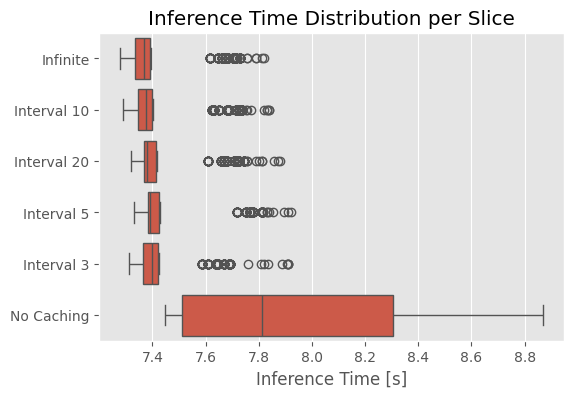

In [14]:
ax = enc5_comparison.plot_inference_times('slice', 'seconds')

In [15]:
enc4_comparison = ModelComparison(
  [baseline, enc4_int3, enc4_int5, enc4_int10, enc4_int20, enc4_int50, enc4_int100, enc4_int200, enc4_inf],
  ['No Caching', 'Interval 3', 'Interval 5', 'Interval 10', 'Interval 20', 'Interval 50', 'Interval 100', 'Interval 200', 'Infinite']
)

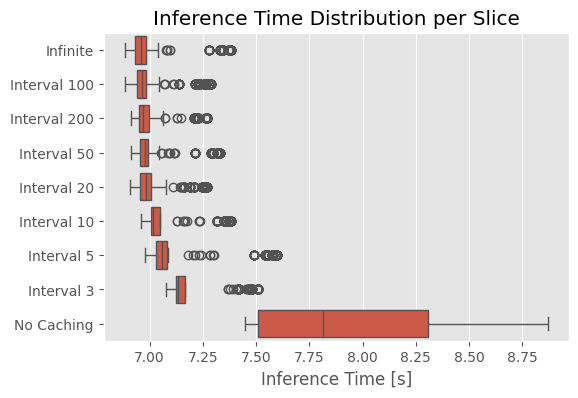

In [16]:
ax = enc4_comparison.plot_inference_times('slice', 'seconds')

In [17]:
enc3_comparison = ModelComparison(
  [baseline, enc3_int3, enc3_int5, enc3_int10, enc3_int20, enc3_int50, enc3_int100, enc3_int200, enc3_inf],
  ['No Caching', 'Interval 3', 'Interval 5', 'Interval 10', 'Interval 20', 'Interval 50', 'Interval 100', 'Interval 200', 'Infinite']
)

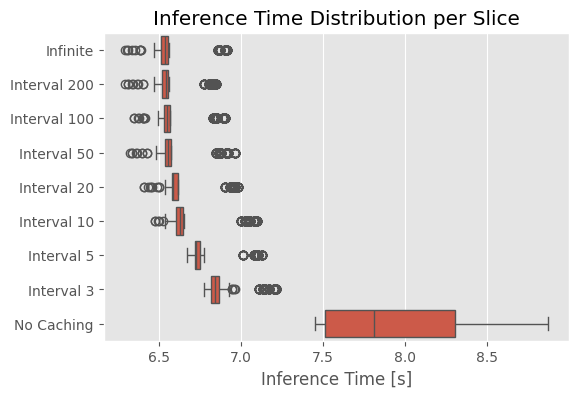

In [18]:
ax = enc3_comparison.plot_inference_times('slice', 'seconds')

In [19]:
enc2_comparison = ModelComparison(
  [baseline, enc2_int3, enc2_int5, enc2_int10, enc2_int20],
  ['No Caching', 'Interval 3', 'Interval 5', 'Interval 10', 'Interval 20']
)

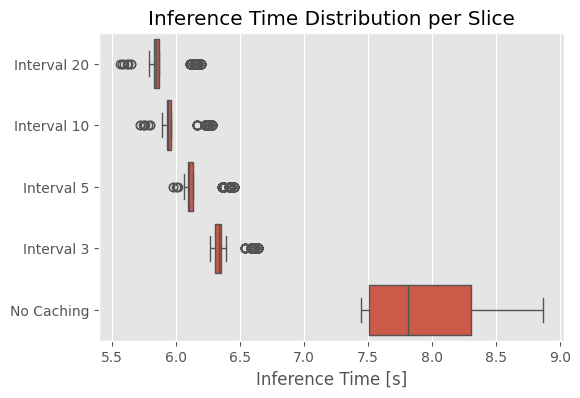

In [20]:
ax = enc2_comparison.plot_inference_times('slice', 'seconds')

In [21]:
enc1_comparison = ModelComparison(
  [baseline, enc1_int3, enc1_int5, enc1_int10, enc1_int20],
  ['No Caching', 'Interval 3', 'Interval 5', 'Interval 10', 'Interval 20']
)

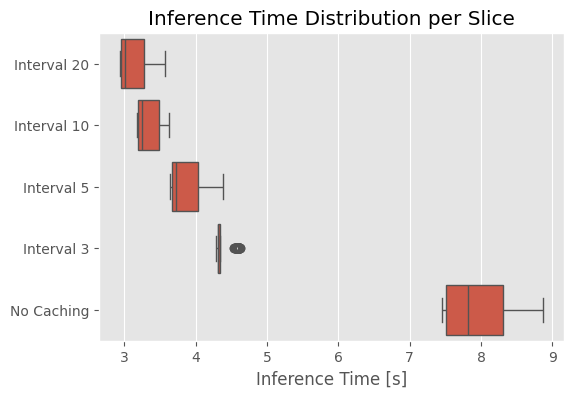

In [22]:
ax = enc1_comparison.plot_inference_times('slice', 'seconds')

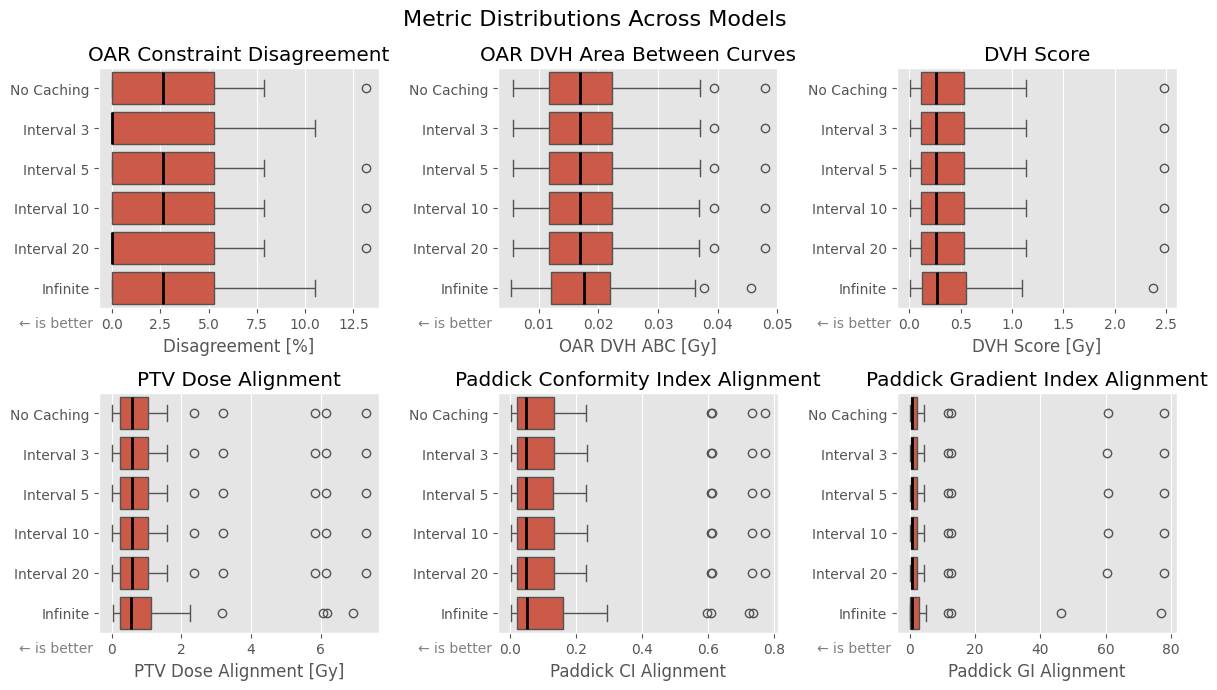

In [23]:
_ = enc5_comparison.plot_metric_distributions(METRICS_PRED)

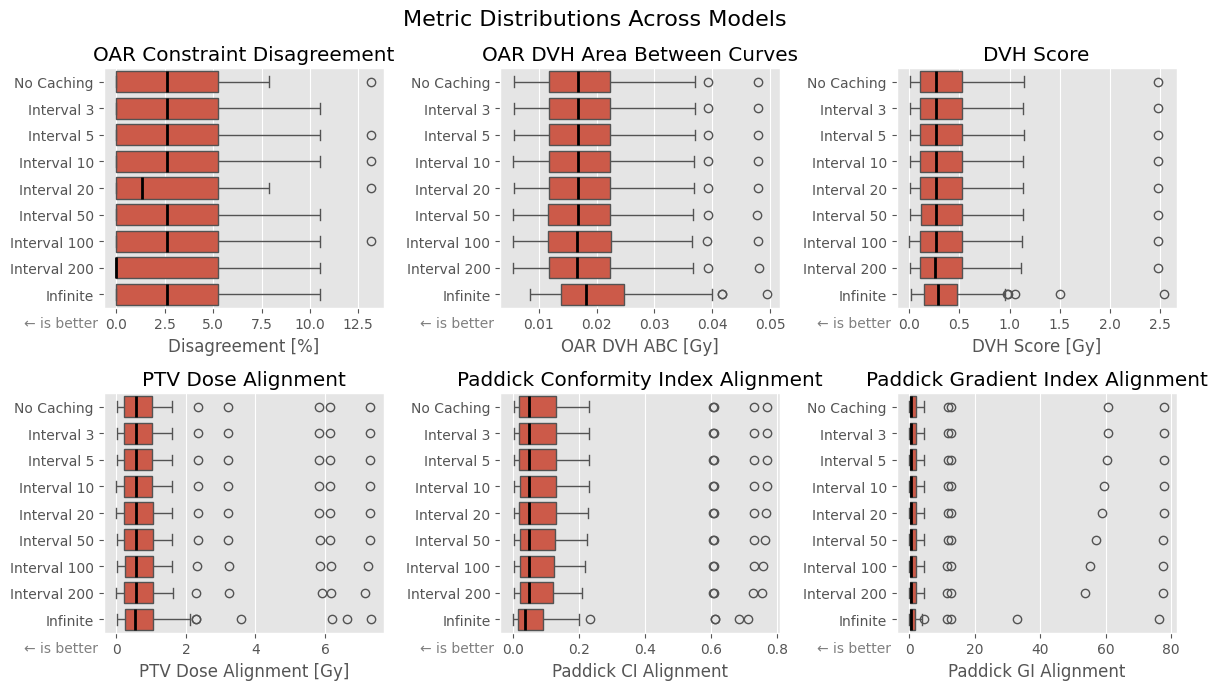

In [24]:
_ = enc4_comparison.plot_metric_distributions(METRICS_PRED)

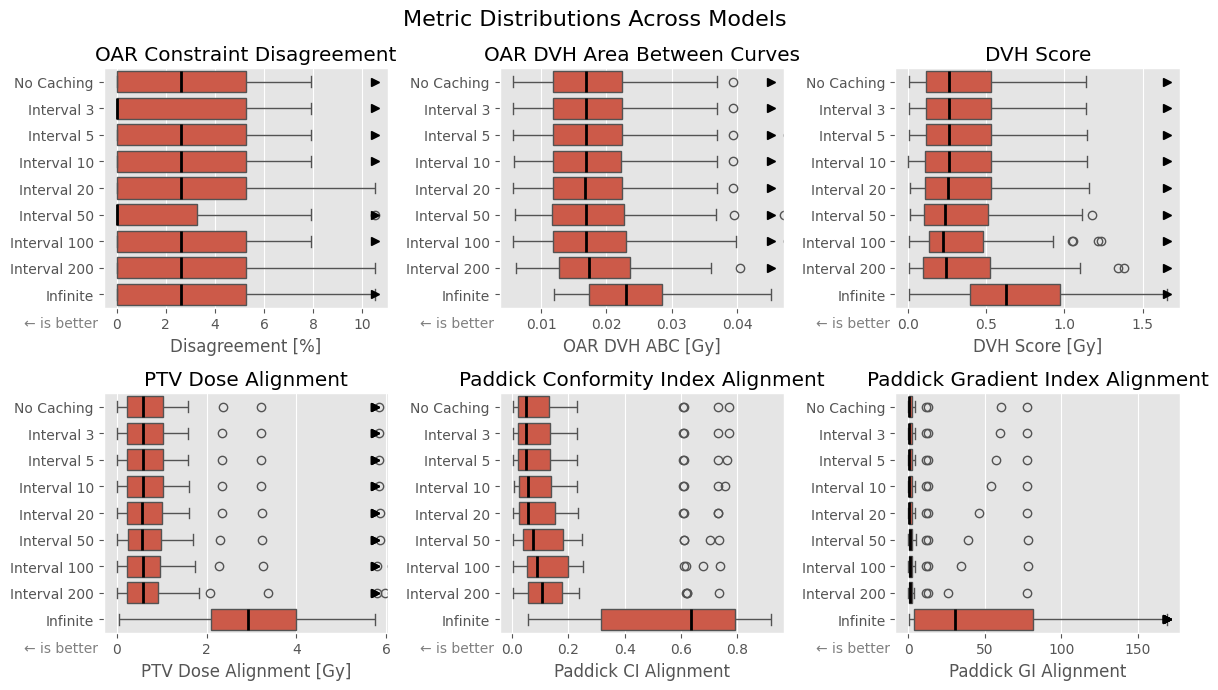

In [25]:
_ = enc3_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

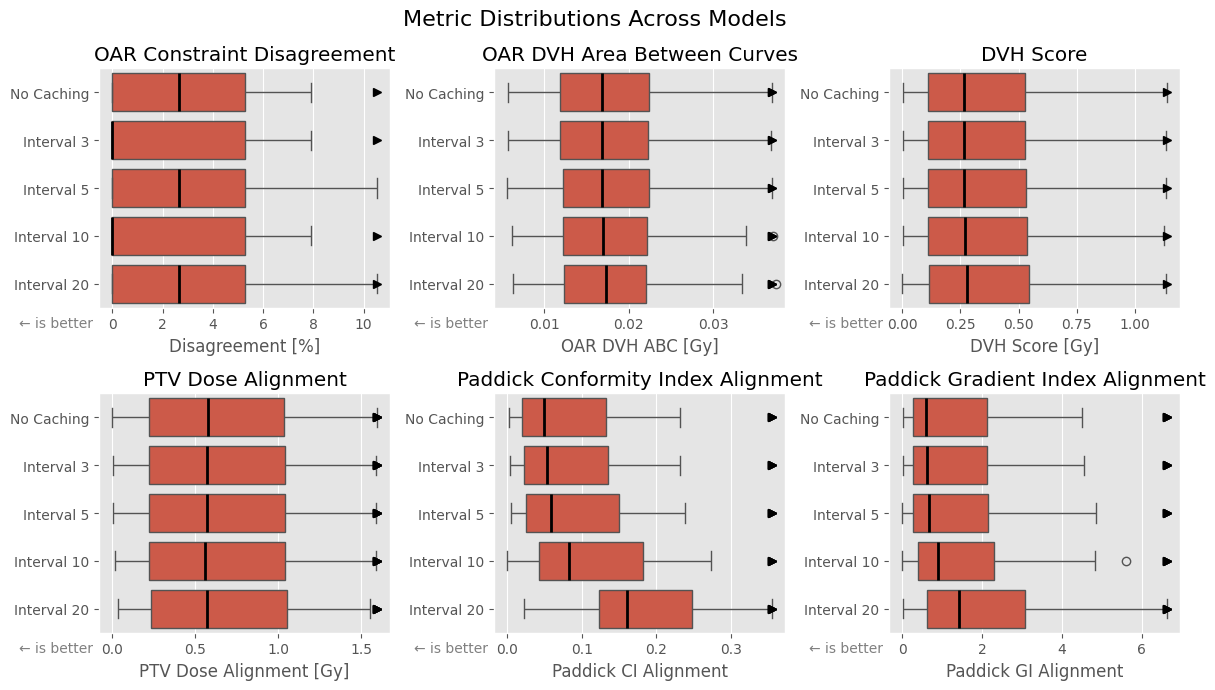

In [26]:
_ = enc2_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

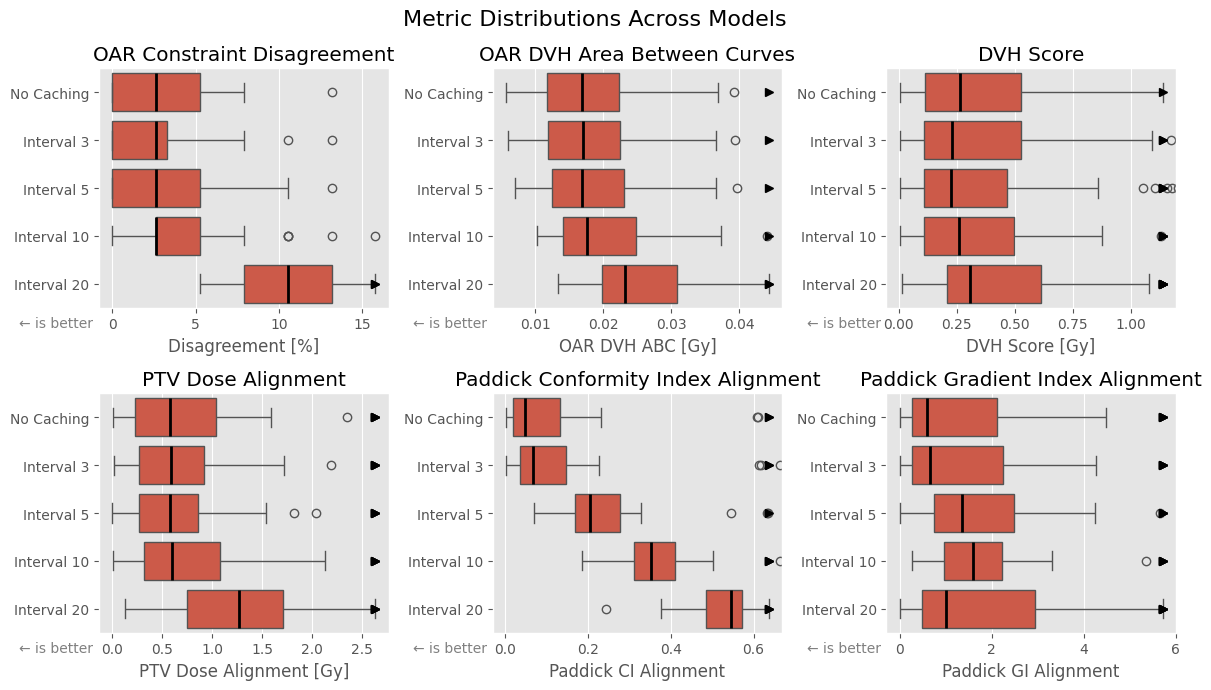

In [27]:
_ = enc1_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

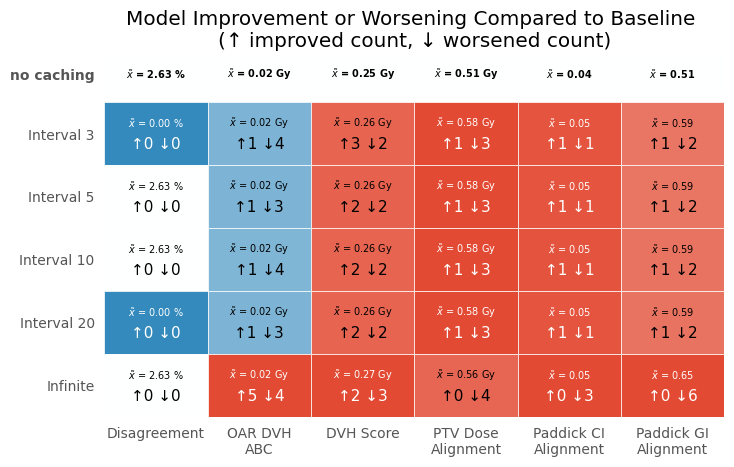

In [29]:
_ = (enc5_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)

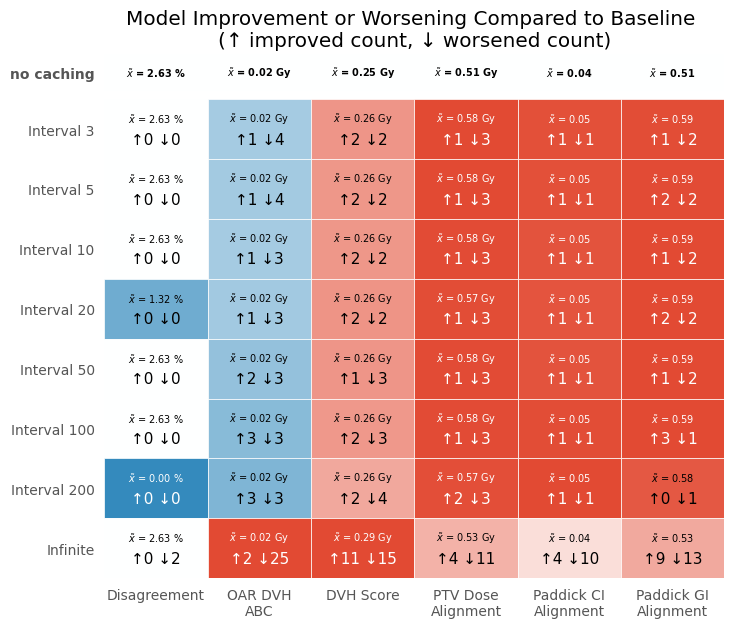

In [30]:
_ = (enc4_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)

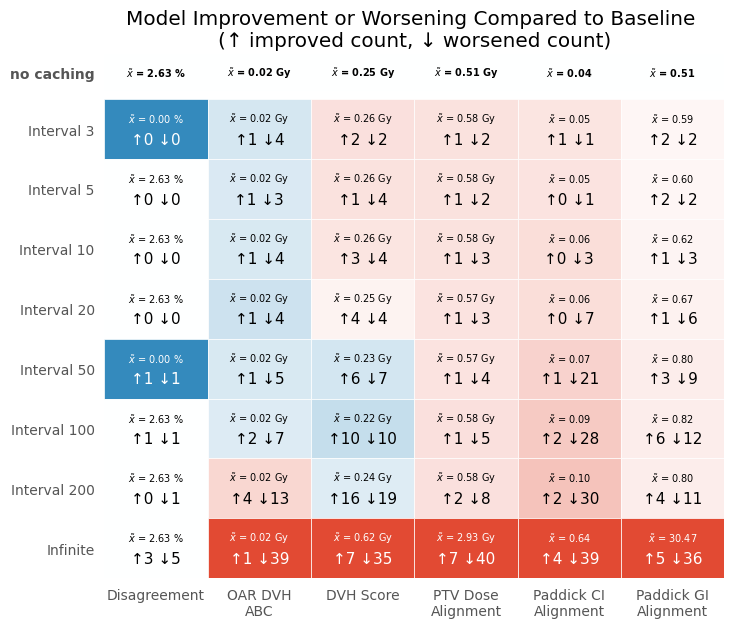

In [40]:
_ = (enc3_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)

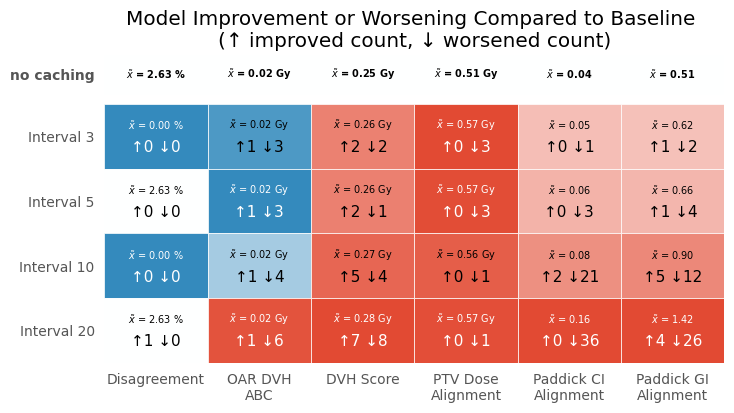

In [32]:
_ = (enc2_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)

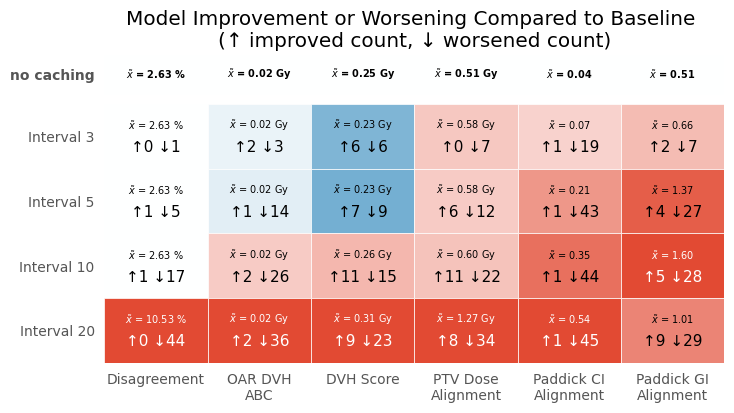

In [33]:
_ = (enc1_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)

1 -> no caching
2 -> 5
3 -> 20
4 -> 200
5 -> inf

no high number in worse volumes

if layers time-independent, also useful for T reduction techniques

## Optimized Version

In [35]:
optimised_comparison = ModelComparison(
  [baseline, optimised],
  ['No Caching', 'Optimised Caching']
)

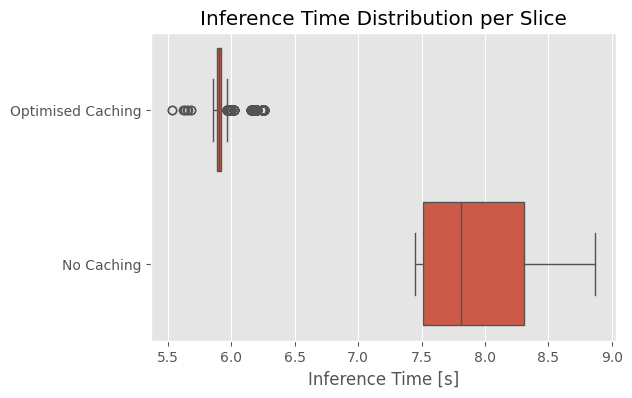

In [36]:
_ = optimised_comparison.plot_inference_times('slice', 'seconds')

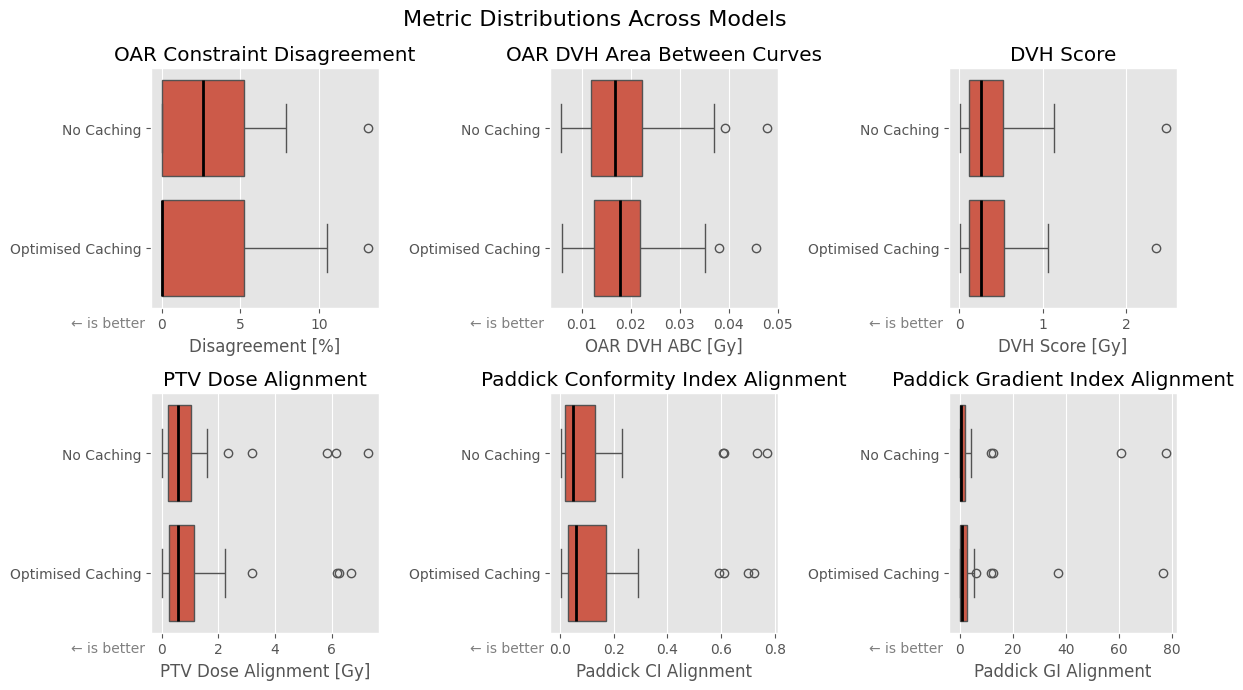

In [37]:
_ = optimised_comparison.plot_metric_distributions(METRICS_PRED)

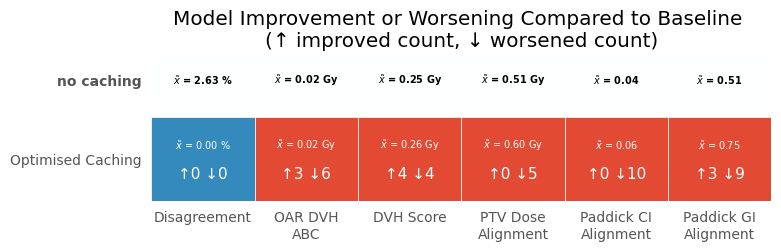

In [38]:
_ = (optimised_comparison - baseline).plot_metric_heatmap(
  METRICS_PRED,
  baseline=baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='no caching'
)